# Local registration with ICP

In the RGBD folder we have the first 400 images from one of the datasets from: [http://redwood-data.org/indoor_lidar_rgbd/download.html](http://redwood-data.org/indoor_lidar_rgbd/download.html)

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# Helper for visualizing two point clouds together.
# Why copy.deepcopy(): open3d's transform()/paint_uniform_color() methods
# modify a point cloud in place. Deep-copying source/target first means calling
# this function never alters the original point clouds.
# Why the optional recolor flag: when comparing two point clouds, it can be
# hard to tell which points belong to 'source' vs. 'target' if they're both
# rendered in their original scan colors. Painting them two distinct, contrasting
# uniform colors (orange and blue) makes the alignment between the two clouds
# much easier to judge by eye.
# Why the optional transformation: passing a 4x4 transformation matrix applies
# that transform to a copy of 'source' before displaying it. This is how we
# visually check whether a computed registration actually aligns the two point
# clouds correctly.
def draw_registrations(source, target, transformation=None, recolor=False):
    source_temp = copy.deepcopy(source)
    target_temp = copy.deepcopy(target)
    if recolor:
        source_temp.paint_uniform_color([1, 0.706, 0])
        target_temp.paint_uniform_color([0, 0.651, 0.929])
    if transformation is not None:
        source_temp.transform(transformation)
    o3d.visualization.draw_geometries([source_temp, target_temp])

In [3]:
# Define a preprocessing pipeline: downsample each point cloud and extract FPFH
# features for use in RANSAC-based matching.
# Why downsample first (voxel_down_sample): raw point clouds can contain millions
# of points. Working with every single one would make normal estimation, feature
# computation, and matching extremely slow. Voxel downsampling divides 3D space
# into a grid of small cubes ("voxels") and keeps roughly one representative
# point per voxel, giving a much smaller but still representative point cloud.
# Why estimate normals (estimate_normals): a normal is the direction a small
# local surface patch is "facing". Many downstream operations need this local
# surface orientation information, which isn't directly present in a raw
# (x, y, z) point cloud and has to be estimated from each point's neighborhood.
# Why these specific parameters scale with voxel_size: radius_normal (2x voxel_size)
# and radius_feature (5x voxel_size) are both defined relative to the
# downsampling voxel size rather than as fixed constants. This keeps the
# neighborhood search radius proportional to the point spacing after
# downsampling, so the same preprocessing function behaves sensibly across point
# clouds of different original density/scale.
# Why FPFH features (compute_fpfh_feature): Fast Point Feature Histograms
# summarize the local geometric shape around each point (based on relationships
# between it and its neighbors' normals) into a numeric descriptor. Conceptually
# the 3D-point-cloud equivalent of a 2D feature descriptor like SIFT, letting us
# later find candidate correspondences between the two point clouds based on
# how similar their local shapes are, without needing any initial alignment guess.
def preprocess_point_cloud(pcd, voxel_size):
    print(":: Downsample with a voxel size %.3f." % voxel_size)
    pcd_down = pcd.voxel_down_sample(voxel_size)

    radius_normal = voxel_size * 2
    print(":: Estimate normal with search radius %.3f." % radius_normal)
    pcd_down.estimate_normals(
        o3d.geometry.KDTreeSearchParamHybrid(radius=radius_normal, max_nn=30)
    )

    radius_feature = voxel_size * 5
    print(":: Compute FPFH feature with search radius %.3f." % radius_feature)
    pcd_fpfh = o3d.pipelines.registration.compute_fpfh_feature(
        pcd_down,
        o3d.geometry.KDTreeSearchParamHybrid(
            radius=radius_feature, max_nn=100
        ),
    )
    return pcd_down, pcd_fpfh

## Creating point clouds from image data
Now we are going to try to create our own point clouds from RGB+depth images.
First, we load two RGBD images.

In [4]:
# Load a pair of RGB + depth images from the Redwood indoor dataset.
# Why RGB and depth: a normal color photo alone only tells us how a scene looks
# in 2D. It has no information about how far away each pixel actually is.
# Pairing it with a depth image (where each pixel value encodes distance from
# the camera instead of color) gives us everything needed to reconstruct the
# scene in 3D.
# Why frames 000000 and 000005: these are two RGBD frames taken only a few
# frames apart in the same video sequence, so the camera has only moved a small
# amount between them.
# Read in images. We have images 000000 - 0000400.
color_raw0 = o3d.io.read_image("RGBD/color/000000.jpg")
depth_raw0 = o3d.io.read_image("RGBD/depth/000000.png")

color_raw1 = o3d.io.read_image("RGBD/color/000005.jpg")
depth_raw1 = o3d.io.read_image("RGBD/depth/000005.png")

Create point clouds from rgb + depth images.

If you set `convert_rgb_to_intensity = False` you will retain the colors from the rgb image.

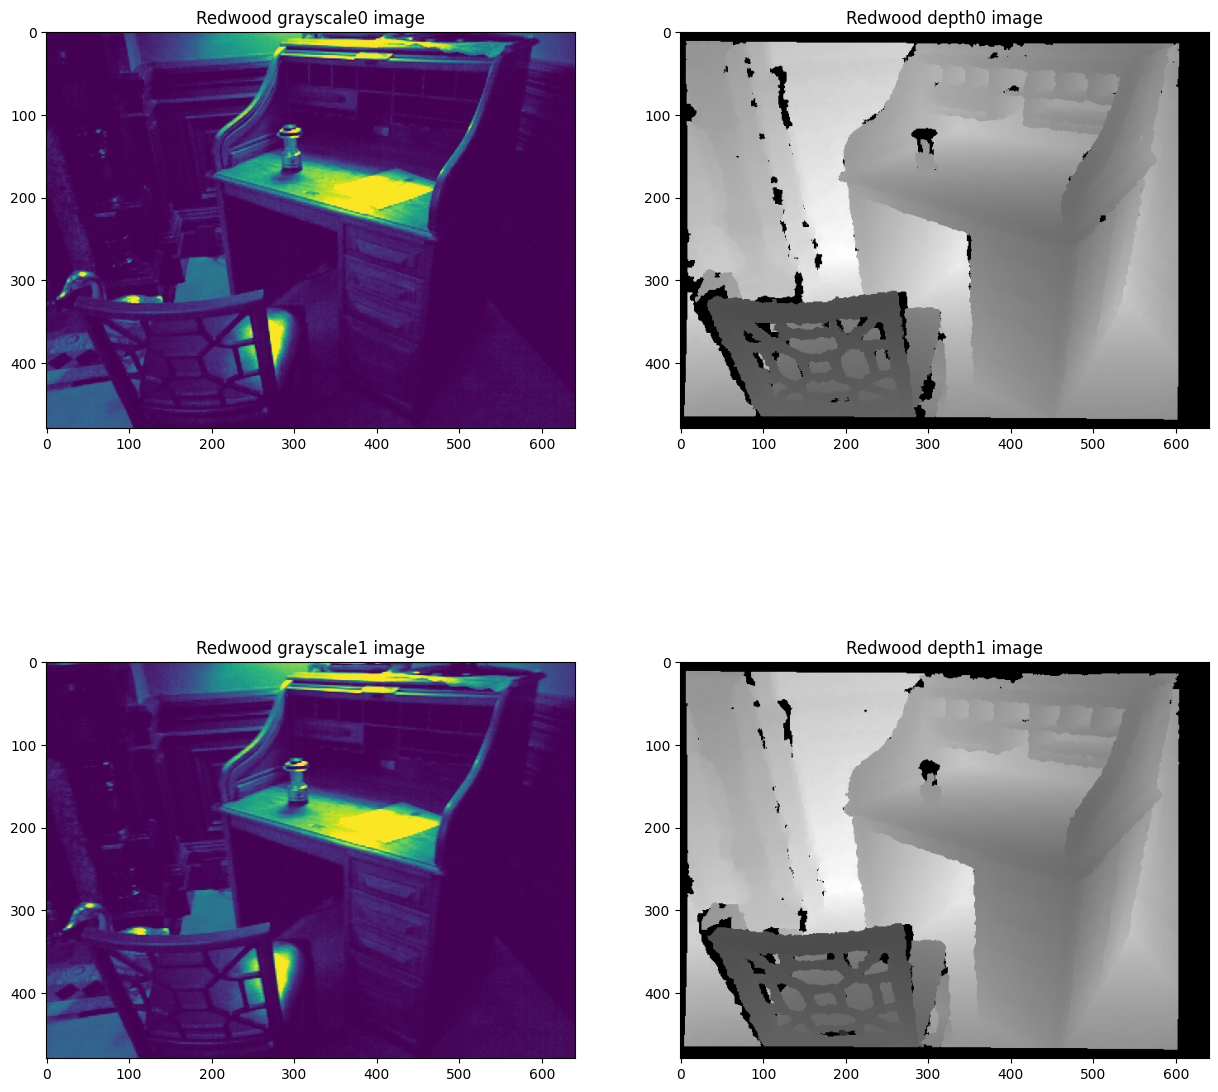

In [5]:
# Combine each color+depth image pair into a single RGBDImage object, then
# visually preview both channels of both frames.
# Why create_from_color_and_depth(): this open3d helper packages a color image
# and its corresponding depth image together into one structure that later
# functions expect as input, rather than having to juggle the two images separately.
# Why convert_rgb_to_intensity=True: this collapses the color image down to
# grayscale intensity internally.
# Why plot both color and depth side by side: this is a basic sanity check that
# both images loaded correctly and are properly aligned/paired before doing
# anything more complex with them. Depth images typically display as a
# grayscale-like heatmap where pixel brightness represents distance from the camera.
rgbd_image0 = o3d.geometry.RGBDImage.create_from_color_and_depth(
    color_raw0, depth_raw0, convert_rgb_to_intensity=True
)

rgbd_image1 = o3d.geometry.RGBDImage.create_from_color_and_depth(
    color_raw1, depth_raw1, convert_rgb_to_intensity=True
)

fig = plt.figure(figsize=(15, 15))
plt.subplot(221)
plt.title("Redwood grayscale0 image")
plt.imshow(rgbd_image0.color)

plt.subplot(222)
plt.title("Redwood depth0 image")
plt.imshow(rgbd_image0.depth, cmap="gray")

plt.subplot(223)
plt.title("Redwood grayscale1 image")
plt.imshow(rgbd_image1.color)

plt.subplot(224)
plt.title("Redwood depth1 image")
plt.imshow(rgbd_image1.depth, cmap="gray")

plt.show()

## Images to point cloud
Now we create point clouds from the RGBD images we just loaded/created.


Here, we use `PinholeCameraIntrinsicParameters.PrimeSenseDefault` as default camera parameters. 

It has an image resolution of 640x480, focal length of ($f_x$, $f_y$) = (525.0, 525.0), and optical center ($c_x$, $c_y$) = (319.5, 239.5). 

An identity matrix is used as default extrinsic parameters. `pcd.transform` applies an up-down flip transformation on the point cloud for an improved visualization.


If execution becomes too slow you can downsample the point cloud.

In [6]:
# Convert each RGBDImage into a 3D point cloud, using a pinhole camera model to
# reproject every pixel's (row, column, depth) into a real (x, y, z) 3D point.
# Why a camera intrinsic model is needed: an RGBD image is still a 2D grid of
# pixels, each with a depth value. Turning that into 3D points requires knowing
# the camera's focal length and optical center (its "intrinsic" parameters),
# which describe exactly how 3D points project onto the 2D image plane.
# PrimeSenseDefault supplies a standard set of these parameters matching the
# sensor this dataset was captured with.
# Why create_from_rgbd_image(): given the RGBD image and camera intrinsics, this
# function performs that reprojection for every pixel, producing 'source'/'target'
# point clouds directly from the two loaded frames.
# Why the flip transform: image-derived point clouds commonly come out with the
# Y and Z axes oriented so the scene appears upside-down/inverted relative to
# typical 3D-viewer conventions; applying this fixed 4x4 transformation
# (flipping Y and Z) simply re-orients the point cloud for a more right-side-up
# visualization. It doesn't affect the actual registration math, only how things
# look on screen.
# Source pointcloud.
camera = o3d.camera.PinholeCameraIntrinsic(
    o3d.camera.PinholeCameraIntrinsicParameters.PrimeSenseDefault
)

source = o3d.geometry.PointCloud.create_from_rgbd_image(rgbd_image0, camera)

# Target pointcloud.
target = o3d.geometry.PointCloud.create_from_rgbd_image(rgbd_image1, camera)

# Flip it, otherwise the pointcloud will be upside down.
source.transform([[1, 0, 0, 0], [0, -1, 0, 0], [0, 0, -1, 0], [0, 0, 0, 1]])
target.transform([[1, 0, 0, 0], [0, -1, 0, 0], [0, 0, -1, 0], [0, 0, 0, 1]])

# draw_registrations(source, target, recolor=True)

PointCloud with 263848 points.

### Evaluation of pointclouds

Before we can run ICP, we evaluate our source and target point clouds. This gives us a feeling if we need a better initial transformation or not.
From (http://www.open3d.org/docs/latest/tutorial/Basic/icp_registration.html):

"The function `evaluate_registration` calculates two main metrics. 
- `fitness` measures the overlapping area (# of inlier correspondences / # of points in target). The higher the better. 
- `inlier_rmse` measures the RMSE of all inlier correspondences. The lower the better.

In [7]:
# Evaluate how well 'source' and 'target' already align under a given initial
# transformation, before attempting to refine that alignment with ICP.
# Why evaluate first, before running ICP: ICP is a local refinement method. it
# can only fix small misalignments, not find a good alignment from scratch.
# Checking the fitness/RMSE of a candidate starting transformation up front
# tells us whether that starting guess is even in the right ballpark, or whether
# ICP is likely to get stuck in the wrong alignment (a "local optimum") if we
# proceed with it.
# Why trans_init is just the identity matrix here: since frames 000000 and
# 000005 are close together in time, assuming "no transformation needed yet"
# (identity) is a reasonable starting guess. The two camera positions likely
# haven't moved far apart, so it's plausible the point clouds are already
# roughly aligned without an explicit initial transform.
# Why threshold = 0.02: this sets how close two points need to be (in the point
# cloud's units) to be counted as a matching "inlier" pair during evaluation.
threshold = 0.02
trans_init = np.asarray(
    [[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]]
)

# Evaluate registration.
print("Initial alignment")
evaluation = o3d.pipelines.registration.evaluate_registration(
    source, target, threshold, trans_init
)
print(evaluation)

Initial alignment
RegistrationResult with fitness=9.176427e-01, inlier_rmse=9.789196e-03, and correspondence_set size of 240059
Access transformation to get result.


## ICP

Now try to call icp with your point clouds and your initial transformation.

Initially we use:
```Python
point_to_plane =  o3d.pipelines.registration.TransformationEstimationPointToPlane()
icp_result = o3d.pipelines.registration.registration_icp(
    source, target, threshold, trans_init,
    point_to_plane)
```

In [8]:
# Why preprocess first: note that unlike the initial evaluate_registration()
# call above, this cell also computes FPFH features via preprocess_point_cloud(),
# even though pure local ICP below doesn't actually need them. This mirrors the
# general "global+local" pipeline pattern used later, without applying it yet,
# since the 5-frame gap case doesn't need RANSAC as a coarse pre-alignment step.
# Why point-to-plane ICP: given the tight 5-frame gap (and thus a reasonable
# starting alignment), point-to-plane's ability to let points slide along the
# target's local surface tends to converge faster/more accurately for this kind
# of scene than the simpler point-to-point variant.
# Why registration_icp(source_down, target_down, ...): note ICP is run on the
# downsampled point clouds (source_down/target_down), not the original
# full-resolution source/target. This keeps ICP's nearest-neighbor search over
# each iteration fast, at the cost of some precision.
voxel_size = 0.05
source_down, source_fpfh = preprocess_point_cloud(source, voxel_size)
target_down, target_fpfh = preprocess_point_cloud(target, voxel_size)

point_to_plane = (
    o3d.pipelines.registration.TransformationEstimationPointToPlane()
)

result = o3d.pipelines.registration.registration_icp(
    source_down, target_down, threshold, trans_init, point_to_plane
)

print(result)
# draw_registrations(source, target, result.transformation, True)
# draw_registrations(source, target, result.transformation)

:: Downsample with a voxel size 0.050.
:: Estimate normal with search radius 0.100.
:: Compute FPFH feature with search radius 0.250.
:: Downsample with a voxel size 0.050.
:: Estimate normal with search radius 0.100.
:: Compute FPFH feature with search radius 0.250.
RegistrationResult with fitness=6.154069e-01, inlier_rmse=1.417079e-02, and correspondence_set size of 2125
Access transformation to get result.


# Exersices

### A)
If you increase the amount of steps from the original image so from i.e. 000000.jpg<>000005.jpg to 00000.jpg<>000300.jpg, what happens?

In [9]:
# Following the RGB-D to point-cloud conversion shown above, this helper loads
# any frame by its ID and returns the corresponding Open3D point cloud.
# This avoids repeating the same loading and reprojection code throughout
# the rest of the exercises.
def load_pcd(frame_id, camera):
    """
    Load one RGB-D frame and convert it into an Open3D point cloud.
    """
    # Read raw data of frame
    color_raw = o3d.io.read_image(f"RGBD/color/{frame_id:06d}.jpg")
    depth_raw = o3d.io.read_image(f"RGBD/depth/{frame_id:06d}.png")
    
    # Get RGBD
    rgbd_image = o3d.geometry.RGBDImage.create_from_color_and_depth(
        color_raw, depth_raw, convert_rgb_to_intensity=True
    )
    
    # Get point cloud
    pcd = o3d.geometry.PointCloud.create_from_rgbd_image(rgbd_image, camera)
    pcd.transform([[1, 0, 0, 0], [0, -1, 0, 0], [0, 0, -1, 0], [0, 0, 0, 1]])
    return pcd

In [10]:
# Why estimate_normals() is called explicitly here: unlike source/target above
# (whose normals get computed inside preprocess_point_cloud() when needed),
# sourceA/targetA are being fed straight into ICP with point-to-plane estimation,
# which specifically requires each point to already have a normal. So normals
# are computed directly on the full-resolution point clouds this time, rather
# than only on a downsampled copy. The evaluate_registration() call, followed
# directly by point-to-plane ICP with the same identity trans_init used for the
# 5-frame case, tests whether that same "assume no initial transform needed"
# assumption still holds at this much larger frame gap.
sourceA = load_pcd(0, camera)
targetA = load_pcd(300, camera)

print("Initial alignment, 000000 <-> 000300")
print(
    o3d.pipelines.registration.evaluate_registration(
        sourceA, targetA, threshold, trans_init
    )
)

sourceA.estimate_normals(
    o3d.geometry.KDTreeSearchParamHybrid(radius=0.1, max_nn=30)
)
targetA.estimate_normals(
    o3d.geometry.KDTreeSearchParamHybrid(radius=0.1, max_nn=30)
)

icp_resultA = o3d.pipelines.registration.registration_icp(
    sourceA,
    targetA,
    threshold,
    trans_init,
    o3d.pipelines.registration.TransformationEstimationPointToPlane(),
)
print("ICP result, 000000 <-> 000300, identity trans_init")
print(icp_resultA)

# draw_registrations(sourceA, targetA, icp_resultA.transformation, True)

Initial alignment, 000000 <-> 000300
RegistrationResult with fitness=5.096635e-02, inlier_rmse=1.196329e-02, and correspondence_set size of 13333
Access transformation to get result.
ICP result, 000000 <-> 000300, identity trans_init
RegistrationResult with fitness=7.855002e-02, inlier_rmse=1.133690e-02, and correspondence_set size of 20549
Access transformation to get result.


With a 300-frame gap the camera has moved (and usually rotated) much further between the two shots, so `source`/`target` share far less true overlap, and the identity `trans_init` that worked for a 5-frame gap is now a much worse guess of the real transform. `evaluate_registration` on the identity guess typically shows a noticeably lower `fitness` than the 5-frame case. Because ICP only searches locally around its starting point, it either converges very slowly / to a poor fit (low fitness, high RMSE), or converges to the wrong local optimum that still looks locally "reasonable" but is not the true alignment (e.g. sliding along a flat wall/floor). ICP alone cannot recover from a bad initial guess.

### B)
Can you tweak the parameters `threshold` and `trans_init` to combat some of the ill effects that starts appearing?


In [11]:
# Why test different thresholds: ICP only considers point pairs within the
# correspondence threshold. With a larger frame gap, the small threshold that
# worked for nearby frames may reject too many potentially useful correspondences.
# Here we keep trans_init fixed and only change the threshold to see its effect.

for threshold_test in [0.02, 0.05, 0.10, 0.20]:
    print("Testing threshold:", threshold_test)
    result = o3d.pipelines.registration.registration_icp(
        sourceA,
        targetA,
        threshold_test,
        trans_init,
        o3d.pipelines.registration.TransformationEstimationPointToPoint(),
    )

    print(":: Fitness: %.3f" % result.fitness)
    print(":: Inlier RMSE: %.3f" % result.inlier_rmse)
    print()

Testing threshold: 0.02
:: Fitness: 0.059
:: Inlier RMSE: 0.012

Testing threshold: 0.05
:: Fitness: 0.163
:: Inlier RMSE: 0.025

Testing threshold: 0.1
:: Fitness: 0.348
:: Inlier RMSE: 0.049

Testing threshold: 0.2
:: Fitness: 0.770
:: Inlier RMSE: 0.066



Increasing the correspondence threshold allows ICP to accept point pairs that are
farther apart. This causes the fitness to increase substantially, since many more
source points can now be matched to the target.

However, the inlier RMSE also increases, meaning that the accepted correspondences
are, on average, farther apart.

This shows why simply increasing `threshold` is not enough to solve a poor initial
alignment. A very large threshold may increase the number of correspondences, but
it can also introduce incorrect or imprecise matches.

Also note that fitness values obtained with different thresholds are not directly
comparable as a measure of registration quality, since increasing the threshold
itself makes it easier for points to be counted as inliers.

In [12]:
# Why chain RANSAC into ICP: RANSAC-based feature matching (via FPFH) can find
# a good coarse alignment from an arbitrary starting position/orientation,
# without needing any prior guess. This is the typical global-to-local strategy:
# RANSAC provides the global alignment, while ICP locally refines that estimate.
# Running it first, then handing its result to ICP as 'trans_init' instead of
# the identity matrix, lets ICP start close enough to the true alignment to
# actually converge correctly via local refinement.
# Why loosen the ICP threshold afterward (0.02 -> 0.05): RANSAC's transformation
# is only an approximate alignment. Even a genuinely good RANSAC result will
# typically have somewhat more residual error than a small handheld-camera
# nudge would. A tight threshold tuned for the near-identity 5-frame case would
# reject too many otherwise-correct point correspondences here; loosening it
# gives ICP enough room to find and use them.

voxel_size = 0.05
sourceA_down, sourceA_fpfh = preprocess_point_cloud(sourceA, voxel_size)
targetA_down, targetA_fpfh = preprocess_point_cloud(targetA, voxel_size)

distance_threshold = voxel_size * 1.5
ransac_result = (
    o3d.pipelines.registration.registration_ransac_based_on_feature_matching(
        sourceA_down,
        targetA_down,
        sourceA_fpfh,
        targetA_fpfh,
        True,
        distance_threshold,
        o3d.pipelines.registration.TransformationEstimationPointToPoint(False),
    )
)
print("RANSAC global registration (used below as ICP's trans_init):")
print(ransac_result)

better_trans_init = ransac_result.transformation
# Loosened from 0.02 to tolerate the residual RANSAC error.
better_threshold = 0.05

icp_resultB = o3d.pipelines.registration.registration_icp(
    sourceA,
    targetA,
    better_threshold,
    better_trans_init,
    o3d.pipelines.registration.TransformationEstimationPointToPlane(),
)
print("ICP result with RANSAC-based trans_init and threshold=0.05")
print(icp_resultB)

# draw_registrations(sourceA, targetA, icp_resultB.transformation, True)

:: Downsample with a voxel size 0.050.
:: Estimate normal with search radius 0.100.
:: Compute FPFH feature with search radius 0.250.
:: Downsample with a voxel size 0.050.
:: Estimate normal with search radius 0.100.
:: Compute FPFH feature with search radius 0.250.
RANSAC global registration (used below as ICP's trans_init):
RegistrationResult with fitness=6.142485e-01, inlier_rmse=3.178758e-02, and correspondence_set size of 2121
Access transformation to get result.
ICP result with RANSAC-based trans_init and threshold=0.05
RegistrationResult with fitness=5.627628e-01, inlier_rmse=1.447052e-02, and correspondence_set size of 147221
Access transformation to get result.


Raising `threshold` alone gives ICP more room to find correspondences, but with a bad `trans_init` it can still converge to the wrong optimum. The reliable fix is to also replace the identity `trans_init` with a coarse **global** registration (RANSAC + FPFH) run once beforehand. This is the standard "global registration for a coarse guess, then local ICP to refine it" pipeline, and it is what lets ICP handle large frame gaps at all.

### C)
Again try to use 
```Python
point_to_plane =  o3d.pipelines.registration.TransformationEstimationPointToPlane()

reg_p2p = o3d.pipelines.registration.registration_icp(
    source, target, threshold, trans_init,
    point_to_plane)
```

This requires you to find the normals for each point cloud use:
```python
    source.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=0.5,
                            max_nn=30),fast_normal_computation=True)
```
Compare the resulting translations of the two methods. Is one better than the other?


In [13]:
# Why fast_normal_computation=True: this trades a small amount of normal-
# estimation accuracy for a significant speedup, useful here since normals are
# being computed on the full-resolution (not downsampled) point clouds.
# Why radius=0.5: since these are full-resolution, non-downsampled point clouds,
# a larger neighborhood radius is used to make sure the normal estimate at each
# point is computed from a reasonably representative local neighborhood, rather
# than an extremely small handful of nearby raw points.
source.estimate_normals(
    o3d.geometry.KDTreeSearchParamHybrid(radius=0.5, max_nn=30),
    fast_normal_computation=True,
)
target.estimate_normals(
    o3d.geometry.KDTreeSearchParamHybrid(radius=0.5, max_nn=30),
    fast_normal_computation=True,
)

point_to_point = (
    o3d.pipelines.registration.TransformationEstimationPointToPoint()
)
point_to_plane = (
    o3d.pipelines.registration.TransformationEstimationPointToPlane()
)

reg_p2p = o3d.pipelines.registration.registration_icp(
    source, target, threshold, trans_init, point_to_point
)
reg_p2l = o3d.pipelines.registration.registration_icp(
    source, target, threshold, trans_init, point_to_plane
)

print("Point-to-point ICP:")
print(reg_p2p)
print("translation:", reg_p2p.transformation[:3, 3])

print("\nPoint-to-plane ICP:")
print(reg_p2l)
print("translation:", reg_p2l.transformation[:3, 3])

# draw_registrations(source, target, reg_p2p.transformation, True)
# draw_registrations(source, target, reg_p2l.transformation, True)

Point-to-point ICP:
RegistrationResult with fitness=9.901951e-01, inlier_rmse=5.394355e-03, and correspondence_set size of 259039
Access transformation to get result.
translation: [ 0.00093672 -0.00060606 -0.00110748]

Point-to-plane ICP:
RegistrationResult with fitness=9.899008e-01, inlier_rmse=5.387130e-03, and correspondence_set size of 258962
Access transformation to get result.
translation: [ 0.00088493 -0.00012749 -0.0009336 ]


For this kind of indoor scene, point-to-plane ICP typically reaches a higher `fitness` / lower `inlier_rmse` in fewer iterations than point-to-point, because it lets a point slide along the target's local surface instead of always pulling straight toward the nearest point that better matches how flat regions actually align. If both runs converge, their translation vectors usually end up close to each other; point-to-plane is the more robust/accurate of the two whenever decent normals are available.

### D)
Extend this and try to see how much of the bedroom you can reconstruct from the RGB and depth images.
You can extend a point cloud by `new = source + target`. Remember to resample the point cloud after a view additions so it does not get too large: `down_source = source.voxel_down_sample(voxel_size=0.05)`

In [14]:
# Why register against the accumulated map, not just the previous single frame:
# if every new frame were only compared against the immediately preceding raw
# frame, small registration errors would compound frame after frame (drift) even
# faster, since each new alignment inherits all previous errors with no
# opportunity to average them out; matching against the growing merged map
# instead lets a new frame align against a more stable picture of the scene,
# reducing (though not eliminating) this drift.
# Why down-sample the merged map after every addition: without this, 'merged'
# would keep accumulating more and more points from every new frame, growing
# unbounded over 400 frames and eventually becoming too slow to register against.
# Re-downsampling back to the same voxel_size after each merge keeps the map's
# point density (and thus its size and registration speed) roughly constant
# regardless of how many frames have been added.
# Why frame_step = 10: this keeps the gap between consecutively registered
# frames small enough that local ICP alone can reliably converge, while still
# covering the full 400-frame sequence in a reasonable number of steps.
# Why prev_transform is reused as the next frame's trans_init: assuming the
# camera moves somewhat consistently between consecutive steps, the previous
# frame's found transformation is usually a much better initial guess for the
# next frame's alignment than starting over from identity each time.
voxel_size = 0.05
threshold_local = 0.05
frame_step = 10  # register every 10th frame -- small enough gap for local ICP
n_frames = 400

merged = load_pcd(0, camera)
merged.estimate_normals(
    o3d.geometry.KDTreeSearchParamHybrid(radius=0.1, max_nn=30)
)
merged = merged.voxel_down_sample(voxel_size)

prev_transform = np.identity(4)

for idx in range(frame_step, n_frames, frame_step):
    new_pcd = load_pcd(idx, camera)
    new_pcd.estimate_normals(
        o3d.geometry.KDTreeSearchParamHybrid(radius=0.1, max_nn=30)
    )
    new_down = new_pcd.voxel_down_sample(voxel_size)

    icp_res = o3d.pipelines.registration.registration_icp(
        new_down,
        merged,
        threshold_local,
        prev_transform,
        o3d.pipelines.registration.TransformationEstimationPointToPlane(),
    )
    new_pcd.transform(icp_res.transformation)
    merged += new_pcd
    merged = merged.voxel_down_sample(voxel_size)
    prev_transform = icp_res.transformation

    print(
        f"frame {idx:>4}: fitness={icp_res.fitness:.3f}  points in map={len(merged.points)}"
    )

# o3d.visualization.draw_geometries([merged])

frame   10: fitness=0.979  points in map=3610
frame   20: fitness=0.996  points in map=3567
frame   30: fitness=0.987  points in map=3794
frame   40: fitness=0.970  points in map=3777
frame   50: fitness=0.964  points in map=3803
frame   60: fitness=0.940  points in map=3883
frame   70: fitness=0.986  points in map=3839
frame   80: fitness=0.987  points in map=3851
frame   90: fitness=0.960  points in map=4092
frame  100: fitness=0.973  points in map=4114
frame  110: fitness=0.994  points in map=4097
frame  120: fitness=0.961  points in map=4443
frame  130: fitness=0.939  points in map=4089
frame  140: fitness=0.940  points in map=4183
frame  150: fitness=0.949  points in map=4169
frame  160: fitness=0.985  points in map=4395
frame  170: fitness=0.994  points in map=4459
frame  180: fitness=0.996  points in map=4336
frame  190: fitness=0.980  points in map=4589
frame  200: fitness=0.976  points in map=4902
frame  210: fitness=0.970  points in map=5202
frame  220: fitness=0.993  points 

Each new frame is registered against the *accumulated map* (not just the previous single frame) so small per-frame errors do not compound as fast, and the map is voxel-down-sampled after every merge so it does not grow without bound over 400 frames. Using the previous frame's transformation as `prev_transform` assumes consecutive registered frames move similarly. If `fitness` starts dropping partway through, that assumption is breaking down and it is worth shrinking `frame_step` or falling back to a global (RANSAC) re-registration for that frame.